Fold 1; 67,305 filas de entrenamiento; 16,826 de validación; 3 épocas; dispositivo: cpu.


,Modelo,Accuracy,Macro F1
0,CNN,0.391,0.384
1,Clase mayoritaria,0.199,0.055


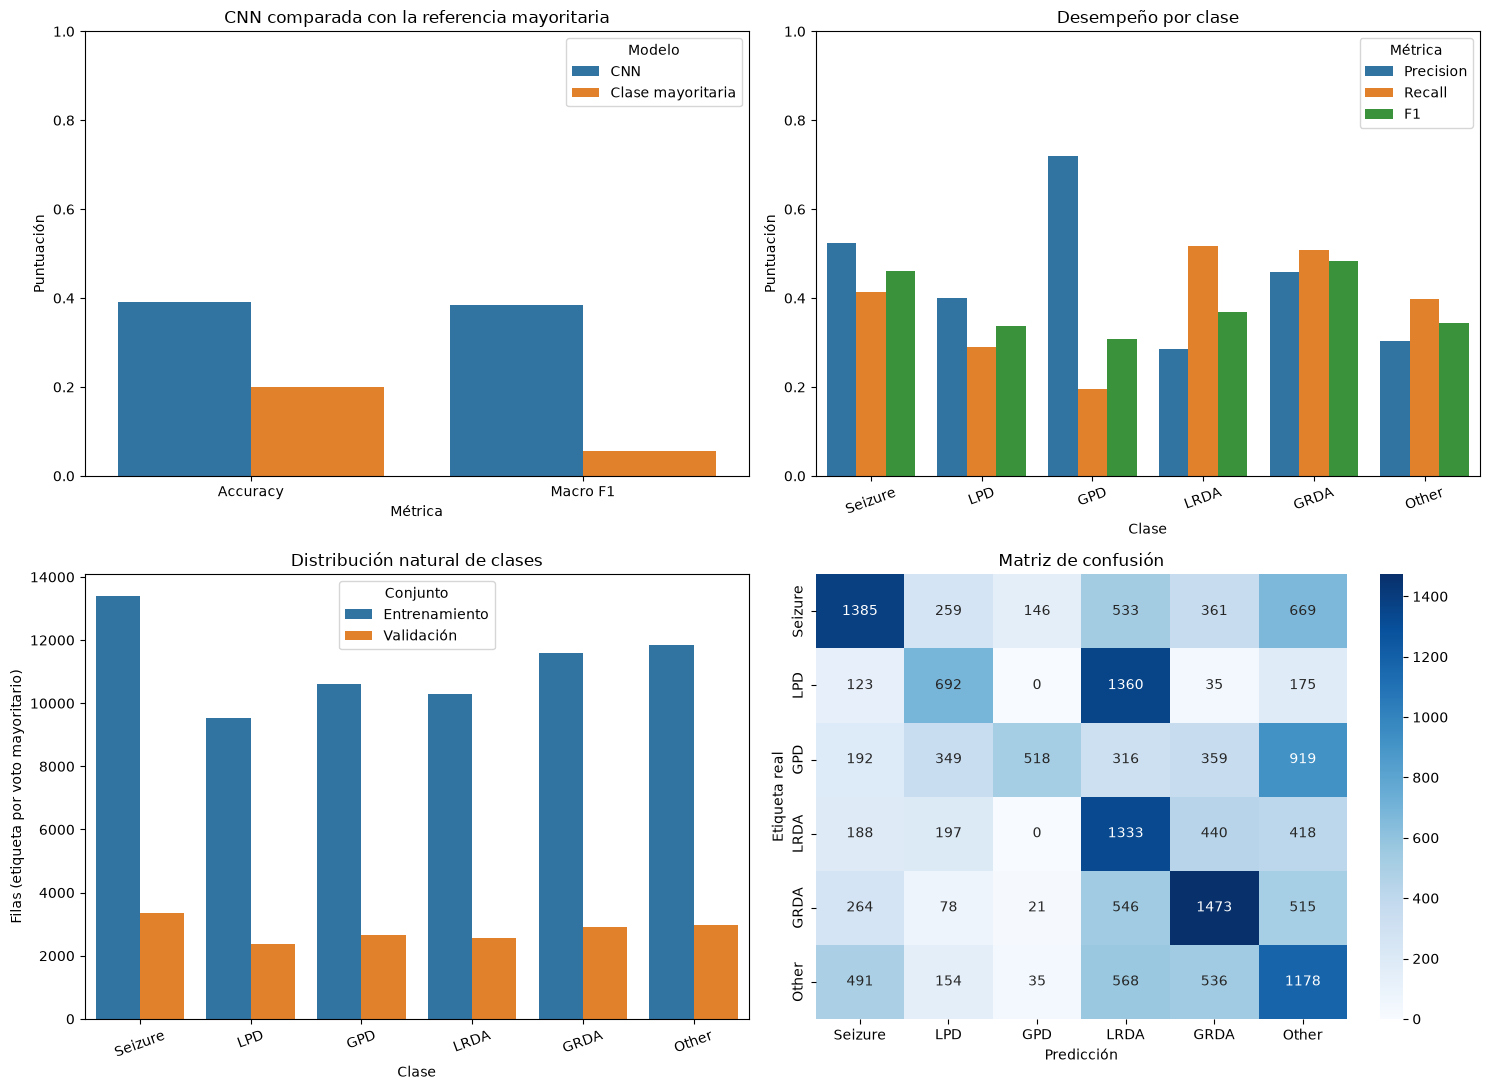

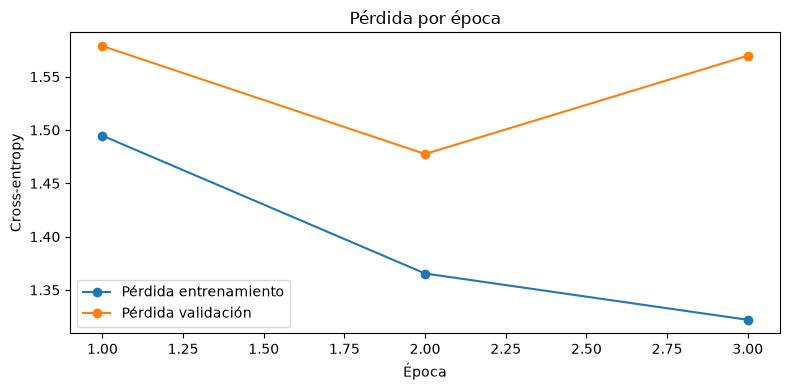

Gráficas guardadas en C:\Users\Jor\Documents\repos\repo_machine_learning\results\figures:
hms_cnn_evaluation_fold_1.png
hms_cnn_loss_fold_1.png


In [1]:
"""04. Métricas y gráficas del experimento completo de desarrollo.

Este informe lee solo métricas guardadas de desarrollo. No entrena, no selecciona hiperparámetros y no lee el holdout final ni el test de Kaggle.
"""
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / "results" / "hms_cnn_experiments.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No encontré results/hms_cnn_experiments.csv. Ejecute primero el notebook 03.")

results_path = PROJECT_ROOT / "results" / "hms_cnn_experiments.csv"
experiments = pd.read_csv(results_path)
full_runs = experiments.loc[experiments["sampling_strategy"].eq("full_development")]
if full_runs.empty:
    raise ValueError("Aún no hay una corrida full_development. Ejecute notebooks/03_modelado.ipynb.")
latest = full_runs.iloc[-1]
class_precision = json.loads(latest["class_precision"])
class_recall = json.loads(latest["class_recall"])
class_f1 = json.loads(latest["class_f1"])
train_counts = json.loads(latest["train_class_counts"])
validation_counts = json.loads(latest["validation_class_counts"])
history = json.loads(latest["training_history"])
confusion = json.loads(latest["confusion_matrix"])
class_names = list(class_precision)

print(f"Fold {int(latest['fold_id'])}; {int(latest['train_samples']):,} filas de entrenamiento; "
      f"{int(latest['validation_samples']):,} de validación; {int(latest['epochs'])} épocas; "
      f"dispositivo: {latest['device']}.")
summary = pd.DataFrame(
    {"Modelo": ["CNN", "Clase mayoritaria"],
     "Accuracy": [latest["cnn_accuracy"], latest["majority_accuracy"]],
     "Macro F1": [latest["cnn_macro_f1"], latest["majority_macro_f1"]]}
)
display(summary.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"}))

figure_directory = PROJECT_ROOT / "results" / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)
figure, axes = plt.subplots(2, 2, figsize=(15, 11))

summary_long = summary.melt(id_vars="Modelo", var_name="Métrica", value_name="Puntuación")
sns.barplot(data=summary_long, x="Métrica", y="Puntuación", hue="Modelo", ax=axes[0, 0])
axes[0, 0].set(title="CNN comparada con la referencia mayoritaria", ylim=(0, 1))

class_metrics = pd.DataFrame(
    {"Clase": class_names, "Precision": class_precision.values(),
     "Recall": class_recall.values(), "F1": class_f1.values()}
).melt(id_vars="Clase", var_name="Métrica", value_name="Puntuación")
sns.barplot(data=class_metrics, x="Clase", y="Puntuación", hue="Métrica", ax=axes[0, 1])
axes[0, 1].set(title="Desempeño por clase", ylim=(0, 1))
axes[0, 1].tick_params(axis="x", rotation=20)

distribution = pd.DataFrame(
    {"Clase": class_names * 2,
     "Filas": list(train_counts.values()) + list(validation_counts.values()),
     "Conjunto": ["Entrenamiento"] * len(class_names) + ["Validación"] * len(class_names)}
)
sns.barplot(data=distribution, x="Clase", y="Filas", hue="Conjunto", ax=axes[1, 0])
axes[1, 0].set(title="Distribución natural de clases", ylabel="Filas (etiqueta por voto mayoritario)")
axes[1, 0].tick_params(axis="x", rotation=20)

sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[1, 1])
axes[1, 1].set(title="Matriz de confusión", xlabel="Predicción", ylabel="Etiqueta real")

figure.tight_layout()
summary_figure = figure_directory / f"hms_cnn_evaluation_fold_{int(latest['fold_id'])}.png"
figure.savefig(summary_figure, dpi=150, bbox_inches="tight")
plt.show()
plt.close(figure)

history_frame = pd.DataFrame(history)
figure, axis = plt.subplots(figsize=(8, 4))
axis.plot(history_frame["epoch"], history_frame["train_loss"], marker="o", label="Pérdida entrenamiento")
axis.plot(history_frame["epoch"], history_frame["validation_loss"], marker="o", label="Pérdida validación")
axis.set(title="Pérdida por época", xlabel="Época", ylabel="Cross-entropy")
axis.legend()
figure.tight_layout()
history_figure = figure_directory / f"hms_cnn_loss_fold_{int(latest['fold_id'])}.png"
figure.savefig(history_figure, dpi=150, bbox_inches="tight")
plt.show()
plt.close(figure)

print(f"Gráficas guardadas en {figure_directory}:")
print(summary_figure.name)
print(history_figure.name)